# 02 - Modelling

Steps covered here:

1. **Evaluation setup**: development set for cross-validation, walk-forward test
2. **Baseline**: how well does the draft pick alone predict VORP in years 3-4?

All rules live in `src/modelling.py`, so every notebook evaluates models the same way.
The test classes (2017-2022) are **not** touched in this notebook.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyRegressor
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import modelling as m
from plot_style import apply_style, BLUE, ORANGE, AQUA, NEUTRAL, INK_2, SURFACE

apply_style()
df = m.load_table()
dev = m.dev_set(df)
print(f"In-scope players: {len(df)}")
print(f"Development set (CV): {len(dev)} players, classes {dev['draft_year'].min()}-{dev['draft_year'].max()}")

In-scope players: 1180
Development set (CV): 683 players, classes 2000-2013


## 1. Evaluation setup

### Development set and folds
Cross-validation uses only players whose target was known before the first test
class played (year 4 ended by 2016-17). Folds group whole draft classes.

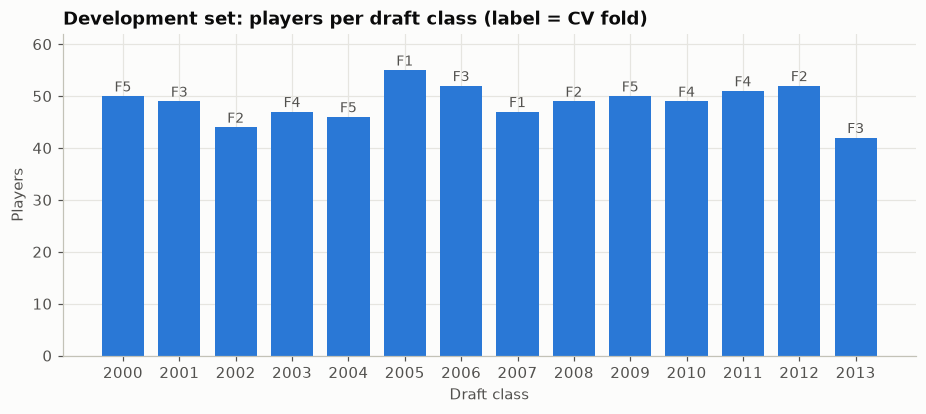

draft_year,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013
players,50,49,44,47,46,55,52,47,49,50,49,51,52,42
fold,5,3,2,4,5,1,3,1,2,5,4,4,2,3


In [2]:
from sklearn.model_selection import GroupKFold

folds = GroupKFold(n_splits=m.N_FOLDS)
fold_of = pd.Series(0, index=dev.index)
for k, (_, va) in enumerate(folds.split(dev, groups=dev["draft_year"])):
    fold_of.iloc[va] = k + 1

per_class = dev.groupby("draft_year").agg(players=("player_id", "size"))
per_class["fold"] = dev.groupby("draft_year").apply(lambda g: fold_of[g.index].iloc[0])

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(per_class.index, per_class["players"], color=BLUE, width=0.75)
for year, row in per_class.iterrows():
    ax.annotate(f"F{row['fold']}", (year, row["players"]), xytext=(0, 3),
                textcoords="offset points", ha="center", fontsize=9, color=INK_2)
ax.set(title="Development set: players per draft class (label = CV fold)",
       xlabel="Draft class", ylabel="Players", ylim=(0, 62))
ax.set_xticks(per_class.index)
plt.show()
per_class.T

**What to look for:** every class sits entirely inside one fold, so a model is
never validated on a class it partly trained on. Fewer players in recent classes
is expected: late debuts from those classes had no completed year 4 by 2016-17.

### Walk-forward test (used only at the very end)
Each test class gets its own model, trained on what was known when that class
played its rookie season.

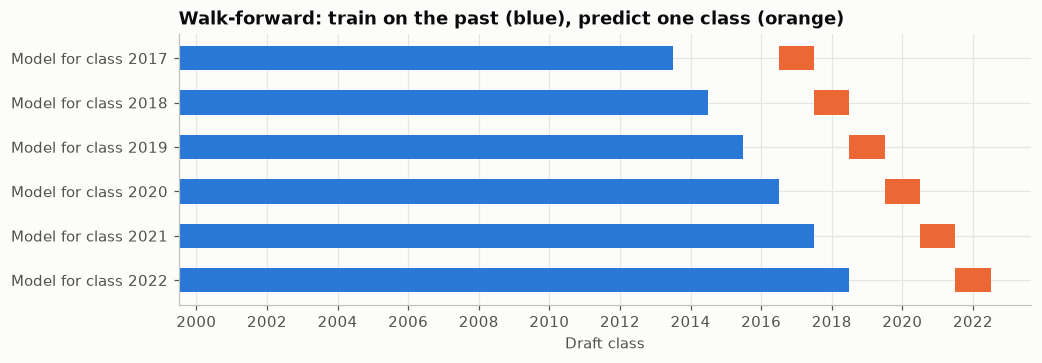

,test class,train players,latest train class,test players
0,2017,683,2013,56
1,2018,735,2014,57
2,2019,783,2015,58
3,2020,837,2016,58
4,2021,897,2017,55
5,2022,955,2018,47


In [3]:
wf = pd.DataFrame({
    "test class": m.TEST_CLASSES,
    "train players": [m.known_before(df, c).sum() for c in m.TEST_CLASSES],
    "latest train class": [df.loc[m.known_before(df, c), "draft_year"].max() for c in m.TEST_CLASSES],
    "test players": [(df["draft_year"] == c).sum() for c in m.TEST_CLASSES],
})

fig, ax = plt.subplots(figsize=(10, 3.2))
for i, row in wf.iterrows():
    ax.barh(i, row["latest train class"] - 2000 + 1, left=2000 - 0.5, color=BLUE, height=0.55)
    ax.barh(i, 1, left=row["test class"] - 0.5, color=ORANGE, height=0.55)
ax.set_yticks(range(len(wf)), [f"Model for class {c}" for c in wf["test class"]])
ax.invert_yaxis()
ax.set(title="Walk-forward: train on the past (blue), predict one class (orange)",
       xlabel="Draft class")
ax.set_xticks(range(2000, 2023, 2))
plt.show()
wf

**What to look for:** the gap between the last blue class and the orange one.
That gap is the time it takes for a class's year 4 to finish: e.g. the model
for 2017 only learns from classes up to ~2013.

## 2. Baseline: draft pick only

The baseline must be **strong**: beating a weak baseline proves nothing.
Candidates, all using only the pick:

| Candidate | Idea |
|---|---|
| Mean only | predicts the average for everyone (the floor, not a real candidate) |
| Linear on pick | a straight line: each pick later loses the same value |
| Quadratic on log(pick) | value falls fast at the top and flattens later |
| Isotonic on pick | any decreasing curve, learned from the data |

Each is scored with the same grouped 5-fold CV.

In [4]:
def log_terms(X):
    lp = np.log(np.asarray(X, dtype=float))
    return np.column_stack([lp, lp ** 2])

CANDIDATES = {
    "Mean only": lambda: DummyRegressor(strategy="mean"),
    "Linear on pick": lambda: LinearRegression(),
    "Quadratic on log(pick)": lambda: make_pipeline(FunctionTransformer(log_terms), LinearRegression()),
    "Isotonic on pick": lambda: IsotonicRegression(increasing=False, out_of_bounds="clip"),
}

results, fold_tables, oof_preds = {}, {}, {}
for name, make in CANDIDATES.items():
    folds_df, oof = m.cross_validate(make, ["pick"], dev)
    fold_tables[name], oof_preds[name] = folds_df, oof
    results[name] = m.summarize(folds_df)

summary = pd.DataFrame(results).T
summary.round(3)

,rmse_mean,mae_mean,spearman_mean,rmse_std,mae_std,spearman_std
Mean only,2.313,1.561,NaN,0.336,0.088,NaN
Linear on pick,2.188,1.423,0.268,0.327,0.088,0.051
Quadratic on log(pick),2.119,1.381,0.268,0.297,0.083,0.052
Isotonic on pick,2.175,1.401,0.250,0.346,0.102,0.056


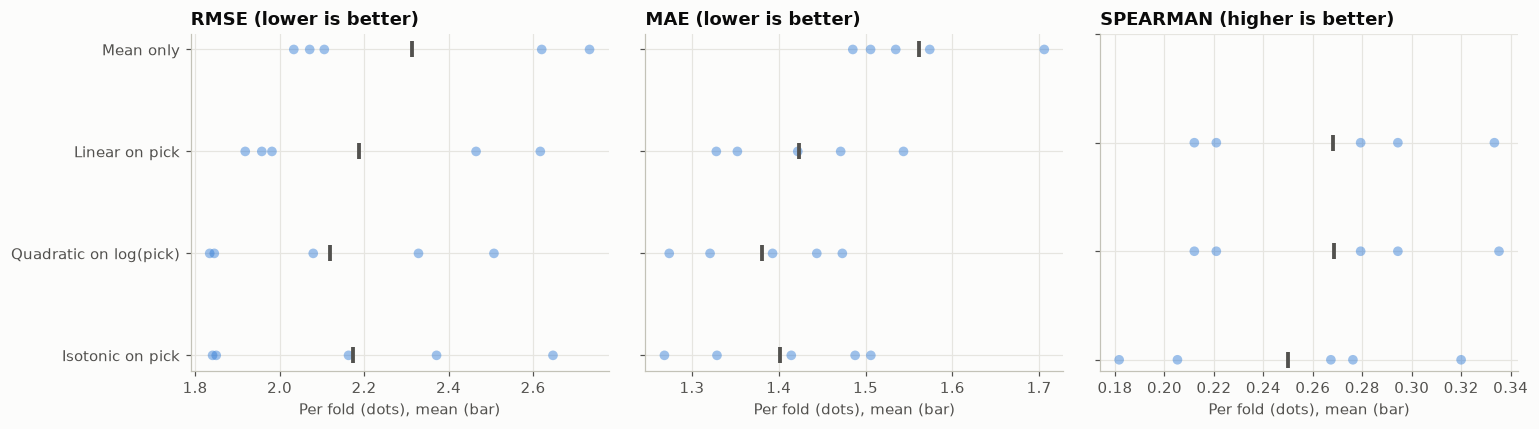

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
names = list(CANDIDATES)
for ax, metric, better in zip(axes, ["rmse", "mae", "spearman"], ["lower", "lower", "higher"]):
    for i, name in enumerate(names):
        vals = fold_tables[name][metric]
        ax.scatter(vals, [i] * len(vals), s=40, color=BLUE, alpha=0.45, edgecolor="none")
        ax.scatter(vals.mean(), i, s=110, marker="|", color=INK_2, linewidths=2.5)
    ax.set_yticks(range(len(names)), names if metric == "rmse" else [""] * len(names))
    ax.invert_yaxis()
    ax.set(title=f"{metric.upper()} ({better} is better)", xlabel="Per fold (dots), mean (bar)")
plt.tight_layout()
plt.show()

**What to look for:** not just which mean is best, but whether a candidate wins
*consistently* across folds (dots shifted together) or only on average. Folds
differ a lot because a single superstar in a fold (e.g. Chris Paul, LeBron)
moves its RMSE.

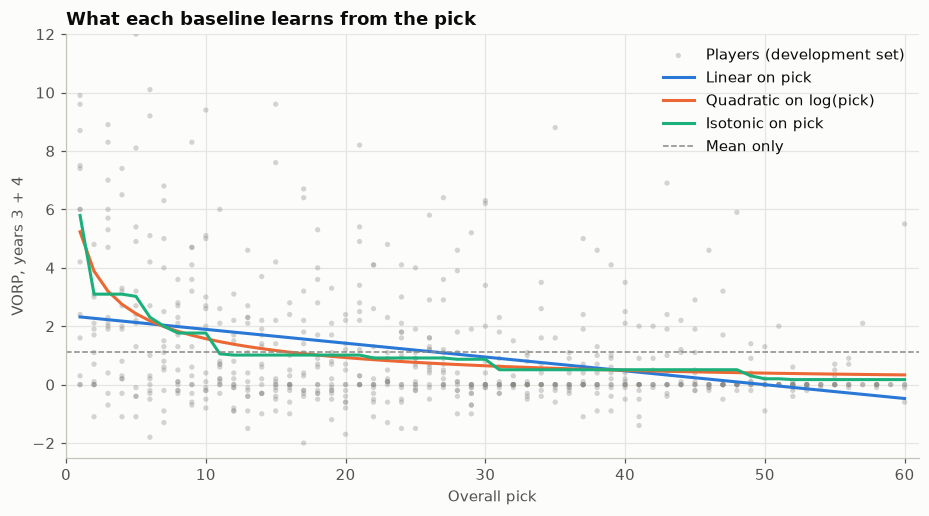

In [6]:
grid = pd.DataFrame({"pick": np.arange(1, 61)})
fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(dev["pick"], dev[m.TARGET], s=12, color=NEUTRAL, alpha=0.35, edgecolor="none",
           label="Players (development set)")
for name, color in zip(names[1:], [BLUE, ORANGE, AQUA]):
    fitted = CANDIDATES[name]().fit(dev[["pick"]], dev[m.TARGET])
    ax.plot(grid["pick"], fitted.predict(grid[["pick"]]), color=color, label=name)
ax.axhline(dev[m.TARGET].mean(), color=NEUTRAL, linewidth=1, linestyle="--", label="Mean only")
ax.set(title="What each baseline learns from the pick", xlabel="Overall pick",
       ylabel="VORP, years 3 + 4", ylim=(-2.5, 12), xlim=(0, 61))
ax.legend(loc="upper right")
plt.show()

**What to look for:** the straight line can't follow the steep drop at the top
picks; the log and isotonic curves can. The y-axis is cut at 12 to show the
curves, so a few stars sit above the plot.

In [7]:
BASELINE = summary["rmse_mean"].drop("Mean only").idxmin()
print(f"Chosen baseline (lowest mean RMSE): {BASELINE}")

# How often does the chosen baseline beat each other candidate, fold by fold?
wins = {name: int((fold_tables[BASELINE]["rmse"] < fold_tables[name]["rmse"]).sum())
        for name in names if name != BASELINE}
print("Folds (out of 5) where it has lower RMSE than:", wins)

Chosen baseline (lowest mean RMSE): Quadratic on log(pick)
Folds (out of 5) where it has lower RMSE than: {'Mean only': 4, 'Linear on pick': 4, 'Isotonic on pick': 4}


,rmse,mae,spearman,n
Picks 1-10,3.522,2.646,0.213,139
Picks 11-30,1.829,1.350,-0.018,267
2nd round,1.238,0.766,0.035,277


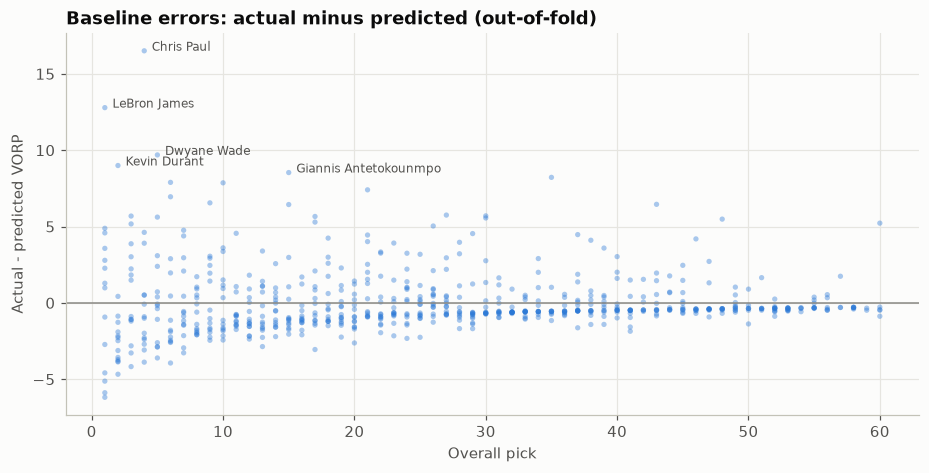

In [8]:
base_oof = oof_preds[BASELINE]
seg = m.by_segment(dev, base_oof)
display(seg.round(3))

fig, ax = plt.subplots(figsize=(10, 4.5))
resid = dev[m.TARGET] - base_oof
ax.scatter(dev["pick"], resid, s=12, color=BLUE, alpha=0.4, edgecolor="none")
ax.axhline(0, color=NEUTRAL, linewidth=1)
for _, row in dev.assign(resid=resid).nlargest(5, "resid").iterrows():
    ax.annotate(row["player_name"], (row["pick"], row["resid"]), xytext=(5, 0),
                textcoords="offset points", fontsize=8, color=INK_2)
ax.set(title="Baseline errors: actual minus predicted (out-of-fold)",
       xlabel="Overall pick", ylabel="Actual - predicted VORP")
plt.show()

**What to look for:** the errors are what the early-game model has to explain.
Big positive errors are steals and stars the pick couldn't see coming; big
negative ones are busts. Errors are much larger at the top picks (where the
stakes are highest), which is why RMSE is the main metric.

In [9]:
cols = ["player_name", "draft_year", "pick", "mpg", "ts_pct", m.TARGET]
view = dev.assign(baseline_pred=base_oof, error=dev[m.TARGET] - base_oof)
print("Baseline's biggest under-predictions (the pick missed a good player)")
display(view.nlargest(8, "error")[cols + ["baseline_pred", "error"]].round(2))
print("Baseline's biggest over-predictions (the pick promised more)")
display(view.nsmallest(8, "error")[cols + ["baseline_pred", "error"]].round(2))

Baseline's biggest under-predictions (the pick missed a good player)


,player_name,draft_year,pick,mpg,ts_pct,target_vorp,baseline_pred,error
239,Chris Paul,2005,4,36.76,-0.01,19.2,2.69,16.51
143,LeBron James,2003,1,40.12,-0.03,17.5,4.71,12.79
147,Dwyane Wade,2003,5,36.22,-0.03,12.0,2.31,9.69
344,Kevin Durant,2007,2,33.32,-0.04,12.8,3.80,9.00
654,Giannis Antetokounmpo,2013,15,19.40,-0.00,9.6,1.06,8.54
621,Draymond Green,2012,35,14.72,-0.11,8.8,0.58,8.22
296,Brandon Roy,2006,6,27.20,-0.05,10.1,2.21,7.89
498,Paul George,2010,10,16.38,-0.06,9.4,1.54,7.86


Baseline's biggest over-predictions (the pick promised more)


,player_name,draft_year,pick,mpg,ts_pct,target_vorp,baseline_pred,error
641,Anthony Bennett,2013,1,10.10,-0.12,0.0,6.18,-6.18
50,Kwame Brown,2001,1,13.50,-0.06,0.3,6.18,-5.88
343,Greg Oden,2007,1,23.05,-0.01,0.0,5.12,-5.12
490,Evan Turner,2010,2,23.88,-0.06,-1.1,3.57,-4.67
291,Andrea Bargnani,2006,1,20.12,-0.03,1.6,6.18,-4.58
293,Adam Morrison,2006,3,33.52,-0.08,-0.7,3.47,-4.17
348,Yi Jianlian,2007,6,27.32,-0.02,-1.8,2.14,-3.94
592,Dion Waiters,2012,4,32.06,-0.06,-1.1,2.78,-3.88


## Baseline result (to beat)

The chosen baseline's cross-validated scores are the bar every model in the next
step has to clear:

In [10]:
baseline_score = summary.loc[BASELINE]
baseline_score.round(3)

rmse_mean        2.119
mae_mean         1.381
spearman_mean    0.268
rmse_std         0.297
mae_std          0.083
spearman_std     0.052
Name: Quadratic on log(pick), dtype: float64